 # **Task 3 – Statistical Analysis and Findings**

**Task 1 – Importing Statistical Analysis Libraries**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import shapiro, kstest, ttest_ind, mannwhitneyu, f_oneway
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm

print("All libraries imported successfully!")

All libraries imported successfully!


What these libraries do ?
pandas → manages datasets.
numpy → performs numerical calculations.
matplotlib → creates graphs.
seaborn → creates statistical plots.
scipy → performs statistical tests.
statsmodels → performs ANOVA and Tukey tests.

**Task 2 – Creating a Synthetic Student Dataset**

Purpose: Create sample student data to perform statistical tests, compare groups, and analyze exam performance.

In [12]:
import pandas as pd
import numpy as np

np.random.seed(42)

data = {
    "Student_ID": range(1, 61),
    "Study_Hours": np.random.randint(1, 10, 60),
    "Study_Group": np.random.choice(["Low", "Medium", "High"], 60),
    "Teaching_Method": np.random.choice(["Online", "Offline"], 60),
    "Exam_Score": np.random.randint(35, 100, 60)
}

df = pd.DataFrame(data)

print(df.head(10))

   Student_ID  Study_Hours Study_Group Teaching_Method  Exam_Score
0           1            7      Medium          Online          37
1           2            4        High          Online          61
2           3            8         Low          Online          43
3           4            5      Medium         Offline          96
4           5            7         Low         Offline          71
5           6            3         Low         Offline          85
6           7            7      Medium          Online          78
7           8            8        High          Online          58
8           9            5         Low          Online          93
9          10            4      Medium         Offline          66


**Task 3 – Exploring and Understanding the Dataset**

Purpose: Check the dataset size, column names, data types, and basic statistical information before performing statistical tests.

In [13]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nStatistical Summary:")
print(df.describe())

print("\nStudy Group Counts:")
print(df["Study_Group"].value_counts())

print("\nTeaching Method Counts:")
print(df["Teaching_Method"].value_counts())

Dataset Shape: (60, 5)

Column Names:
['Student_ID', 'Study_Hours', 'Study_Group', 'Teaching_Method', 'Exam_Score']

Data Types:
Student_ID          int64
Study_Hours         int64
Study_Group        object
Teaching_Method    object
Exam_Score          int64
dtype: object

Statistical Summary:
       Student_ID  Study_Hours  Exam_Score
count   60.000000    60.000000   60.000000
mean    30.500000     5.066667   65.666667
std     17.464249     2.427712   20.609909
min      1.000000     1.000000   35.000000
25%     15.750000     3.000000   49.000000
50%     30.500000     5.000000   66.000000
75%     45.250000     7.000000   86.000000
max     60.000000     9.000000   96.000000

Study Group Counts:
Study_Group
High      24
Low       24
Medium    12
Name: count, dtype: int64

Teaching Method Counts:
Teaching_Method
Online     32
Offline    28
Name: count, dtype: int64


**Task 4 – Distribution Visualization**

Purpose: Visualize the distribution of exam scores and check how the data is spread across different values.

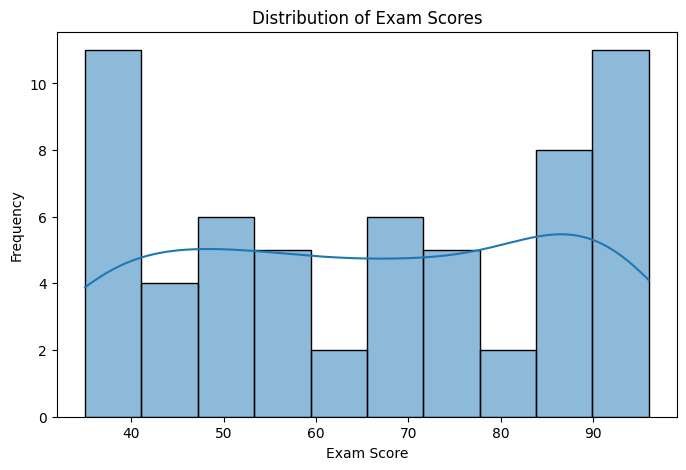

In [4]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Exam_Score", kde=True, bins=10)

plt.title("Distribution of Exam Scores")
plt.xlabel("Exam Score")
plt.ylabel("Frequency")

plt.show()

**Task 5 – Shapiro–Wilk Normality Test**

Purpose: Check whether the Exam_Score data follows a normal distribution.

In [5]:
from scipy.stats import shapiro

statistic, p_value = shapiro(df["Exam_Score"])

print("Shapiro-Wilk Normality Test")
print("Test Statistic:", statistic)
print("P-value:", p_value)

if p_value > 0.05:
    print("Conclusion: Data appears normally distributed.")
else:
    print("Conclusion: Data does not appear normally distributed.")

Shapiro-Wilk Normality Test
Test Statistic: 0.9149707433696418
P-value: 0.0004840632871326642
Conclusion: Data does not appear normally distributed.


Interpretation:
p-value > 0.05 → We do not reject the null hypothesis; the data is consistent with normality.
p-value < 0.05 → We reject the null hypothesis; there is evidence the data deviates from normality.

**Task 6 – Kolmogorov–Smirnov Normality Test**

Purpose: Compare the sample distribution with a normal distribution.

In [11]:
from scipy.stats import kstest, zscore

scores = df["Exam_Score"]

# Standardize the data
standardized_scores = zscore(scores)

statistic, p_value = kstest(standardized_scores, "norm")

print("Kolmogorov-Smirnov Normality Test")
print("Test Statistic:", statistic)
print("P-value:", p_value)

if p_value > 0.05:
    print("Conclusion: No significant difference from normal distribution.")
else:
    print("Conclusion: Significant difference from normal distribution.")

Kolmogorov-Smirnov Normality Test
Test Statistic: 0.13181962386248725
P-value: 0.22720965238575797
Conclusion: No significant difference from normal distribution.


Hypotheses:
H₀: The sample follows a normal distribution.
H₁: The sample does not follow a normal distribution.

**Task 7 – Creating Two Groups for Statistical Comparison**

Purpose: Divide students into two groups based on study hours so we can compare their exam scores using:
Independent two-sample t-test
Mann–Whitney U test

Group 1: Students who study fewer than 5 hours.
Group 2: Students who study 5 hours or more.

In [7]:
group_1 = df[df["Study_Hours"] < 5]["Exam_Score"]
group_2 = df[df["Study_Hours"] >= 5]["Exam_Score"]

print("Group 1: Less than 5 study hours")
print(group_1)

print("\nGroup 2: 5 or more study hours")
print(group_2)

print("\nGroup 1 Size:", len(group_1))
print("Group 2 Size:", len(group_2))

Group 1: Less than 5 study hours
1     61
5     85
9     66
12    92
15    73
18    90
20    36
23    35
24    53
26    87
28    66
30    89
35    45
36    50
38    37
41    70
42    53
45    86
46    67
47    74
48    73
50    45
51    91
54    65
56    41
57    50
58    94
Name: Exam_Score, dtype: int64

Group 2: 5 or more study hours
0     37
2     43
3     96
4     71
6     78
7     58
8     93
10    86
11    96
13    86
14    46
16    36
17    37
19    93
21    36
22    88
25    36
27    78
29    66
31    90
32    51
33    72
34    58
37    93
39    54
40    93
43    53
44    54
49    35
52    84
53    57
55    76
59    36
Name: Exam_Score, dtype: int64

Group 1 Size: 27
Group 2 Size: 33


**Task 8 – Independent Two-Sample t-Test**

Purpose: Determine whether the average exam scores of students who study fewer than 5 hours and those who study 5 hours or more are significantly different.

In [8]:
from scipy.stats import ttest_ind

statistic, p_value = ttest_ind(group_1, group_2, equal_var=False)

print("Independent Two-Sample t-Test")
print("t-Statistic:", statistic)
print("P-value:", p_value)

if p_value < 0.05:
    print("Conclusion: Significant difference between the two groups.")
else:
    print("Conclusion: No significant difference between the two groups.")

Independent Two-Sample t-Test
t-Statistic: 0.012649022559998453
P-value: 0.9899514577416806
Conclusion: No significant difference between the two groups.


Hypotheses:
H₀: There is no significant difference in mean exam scores between the two groups.
H₁: There is a significant difference in mean exam scores between the two groups.

Why equal_var=False?
It uses Welch’s t-test, which does not assume the two groups have equal variances.

**Task 9 – Mann–Whitney U Test**

Purpose: Compare the exam scores of the two study-hour groups using a non-parametric statistical test. It is based on ranks rather than directly comparing means.

In [9]:
from scipy.stats import mannwhitneyu

statistic, p_value = mannwhitneyu(
    group_1,
    group_2,
    alternative="two-sided"
)

print("Mann-Whitney U Test")
print("U-Statistic:", statistic)
print("P-value:", p_value)

if p_value < 0.05:
    print("Conclusion: Significant difference between the two groups.")
else:
    print("Conclusion: No significant difference between the two groups.")

Mann-Whitney U Test
U-Statistic: 437.0
P-value: 0.9053053134848504
Conclusion: No significant difference between the two groups.


Hypotheses:
H₀: There is no significant difference between the two groups.
H₁: There is a significant difference between the two groups.

**Task 10 – One-Way ANOVA**

Purpose: Compare the mean exam scores across three study groups: Low, Medium, and High.

In [10]:
from scipy.stats import f_oneway

low_scores = df[df["Study_Group"] == "Low"]["Exam_Score"]
medium_scores = df[df["Study_Group"] == "Medium"]["Exam_Score"]
high_scores = df[df["Study_Group"] == "High"]["Exam_Score"]

statistic, p_value = f_oneway(
    low_scores,
    medium_scores,
    high_scores
)

print("One-Way ANOVA")
print("F-Statistic:", statistic)
print("P-value:", p_value)

if p_value < 0.05:
    print("Conclusion: Significant difference exists among study groups.")
else:
    print("Conclusion: No significant difference among study groups.")

One-Way ANOVA
F-Statistic: 1.0395559231783285
P-value: 0.3602181479728711
Conclusion: No significant difference among study groups.


Hypotheses:
H₀: All three study groups have equal mean exam scores.
H₁: At least one study group has a different mean exam score.

**Task 11 – Tukey HSD Post-Hoc Test**

Purpose: One-Way ANOVA tells us whether a difference exists somewhere among the three groups. Tukey HSD helps identify which specific groups differ (Low vs Medium, Low vs High, Medium vs High).

In [14]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd

tukey_result = pairwise_tukeyhsd(
    endog=df["Exam_Score"],
    groups=df["Study_Group"],
    alpha=0.05
)

print(tukey_result)

 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower    upper  reject
-----------------------------------------------------
  High    Low   8.4583 0.3362  -5.8492 22.7659  False
  High Medium   2.6667 0.9288 -14.8564 20.1898  False
   Low Medium  -5.7917 0.7074 -23.3148 11.7314  False
-----------------------------------------------------


How to read the results?
reject = True → Significant difference between those groups.
reject = False → No statistically significant difference.
p-adj < 0.05 → Significant difference.

**Task 12 – Two-Way ANOVA**

Purpose: Examine how two factors—Study Group and Teaching Method—affect students' exam scores, including whether their effects interact.

In [15]:
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm

model = ols(
    "Exam_Score ~ Study_Group * Teaching_Method",
    data=df
).fit()

anova_result = anova_lm(model, typ=2)

print("Two-Way ANOVA")
print(anova_result)

Two-Way ANOVA
                                   sum_sq    df         F    PR(>F)
Study_Group                    869.853277   2.0  1.036403  0.361676
Teaching_Method                200.402384   1.0  0.477546  0.492496
Study_Group:Teaching_Method   1317.865723   2.0  1.570196  0.217353
Residual                     22661.106893  54.0       NaN       NaN


Hypotheses:
H₀: Study group, teaching method, and their interaction have no significant effect on exam scores.
H₁: At least one factor or their interaction has a significant effect on exam scores.

**Task 13 – Distribution Plots by Study Group**

Purpose: Compare the distribution of exam scores among Low, Medium, and High study groups using boxplots.
A boxplot helps us visualize:
Median exam score
Spread of scores
Differences between study groups
Potential outliers

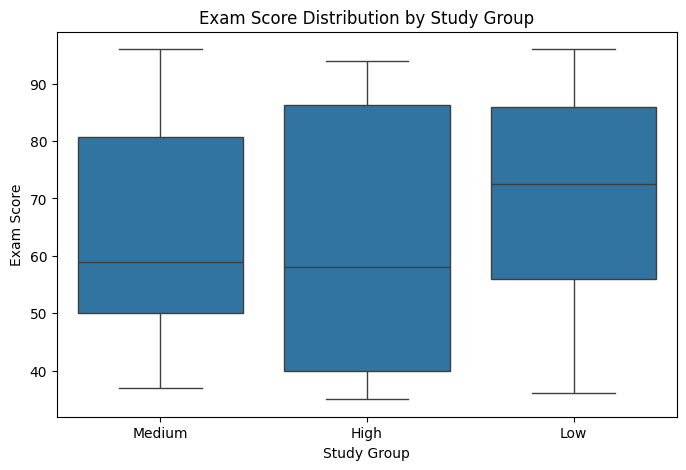

In [16]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Study_Group", y="Exam_Score")

plt.title("Exam Score Distribution by Study Group")
plt.xlabel("Study Group")
plt.ylabel("Exam Score")

plt.show()

**Task 14 – Confidence Interval (95%)**

Purpose: Calculate a 95% confidence interval for the mean exam score. It estimates a range of values within which the population mean may plausibly lie.

In [17]:
from scipy.stats import t

scores = df["Exam_Score"]

mean_score = scores.mean()
std_error = scores.sem()

confidence_interval = t.interval(
    confidence=0.95,
    df=len(scores) - 1,
    loc=mean_score,
    scale=std_error
)

print("95% Confidence Interval for Exam Scores")
print("Mean Score:", mean_score)
print("Lower Bound:", confidence_interval[0])
print("Upper Bound:", confidence_interval[1])

95% Confidence Interval for Exam Scores
Mean Score: 65.66666666666667
Lower Bound: 60.34256253598974
Upper Bound: 70.9907707973436


What it means
Mean Score: Average score of our sample.
Lower Bound: Lowest estimated limit.
Upper Bound: Highest estimated limit.
95% CI: A method that, over repeated samples, would produce intervals containing the true population mean about 95% of the time (under the assumptions).

**Task 15 – Hypotheses and Findings (Markdown Documentation)**

1. Research Objective
The objective of this analysis is to examine student exam scores using statistical methods and investigate differences between study groups and teaching methods.
2. Hypotheses
Normality Tests (Shapiro-Wilk and Kolmogorov-Smirnov)
H₀: The data follows a normal distribution.
H₁: The data does not follow a normal distribution.
Two-Sample t-Test and Mann-Whitney U Test
H₀: There is no significant difference in exam scores between students studying fewer than 5 hours and those studying 5 hours or more.
H₁: There is a significant difference between the two groups.
One-Way ANOVA
H₀: The mean exam scores of Low, Medium, and High study groups are equal.
H₁: At least one group has a different mean exam score.
Two-Way ANOVA
H₀: Study group, teaching method, and their interaction have no significant effect on exam scores.
H₁: At least one factor or interaction has a significant effect on exam scores.
3. Significance Level
The significance level was set at α = 0.05.
p-value < 0.05: Statistically significant result.
p-value ≥ 0.05: Not statistically significant.
4. Statistical Methods
The following methods were used:
Shapiro-Wilk normality test
Kolmogorov-Smirnov normality test
Independent two-sample t-test (Welch's t-test)
Mann-Whitney U test
One-Way ANOVA
Two-Way ANOVA
Tukey HSD post-hoc test
95% confidence interval
5. Limitations
The dataset is synthetic and was created for educational and statistical practice. The results do not represent real student performance and should not be generalized to an actual student population.

**Task 16 – Final Conclusion**


This statistical analysis explored student exam scores using normality tests, hypothesis testing, and analysis of variance methods.
The Shapiro-Wilk and Kolmogorov-Smirnov tests were used to examine normality. Welch's two-sample t-test and Mann-Whitney U test were used to compare two study-hour groups. One-Way ANOVA evaluated differences among study groups, while Two-Way ANOVA examined the effects of study group and teaching method. Tukey HSD was used for post-hoc comparisons, and a 95% confidence interval was calculated to estimate the mean exam score.
The findings should be interpreted based on the obtained p-values and statistical results. Since the dataset is synthetic, the analysis is intended for learning and demonstrating statistical techniques rather than drawing conclusions about real students.